# Formulating decision rules and nonlinear effects in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/13-formulation.ipynb)

This notebook is the Python companion to [Formulating decision rules and nonlinear effects](https://waelrash1.github.io/loopbricks/#/learn/formulation). Writing an equation is easy; writing one that still makes sense when the model is pushed to an extreme is a craft. You will build outflows that cannot empty a stock below zero, a stock adjustment rule that hits its target, a nonlinear effect with sensible limits, and see what happens when a limit is removed.

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Outflows that respect the stock

A rate equation should never ask a stock for more than it has. Below, a hand-written store loses 10 a week while only 3 come in. The equation `Draining = 10` is fine while the store is full and nonsense once it is empty.

Level Protected by Flow

Stocks:
  On hand = INTEG(Replenish − Draining, 80)

Flows:
  Replenish = Replenishment
  Draining = MIN(Desired_draining, On_hand / Fastest_draining_time)

Variables:
  Replenishment = 3
  Desired draining = 10
  Fastest draining time = 2

Naive store at week 60: -340


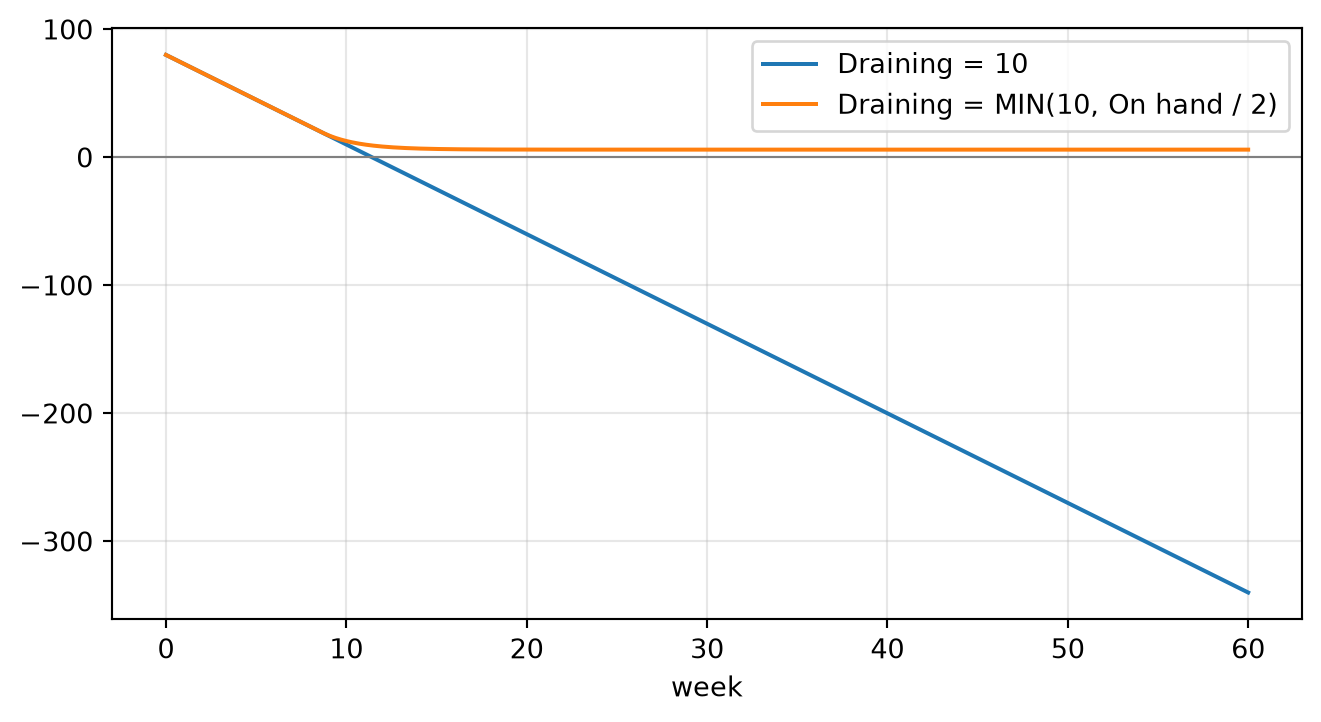

In [2]:
naive = lb.Model.from_spec({
    "name": "Naive drain", "timeUnit": "week", "T": 60, "dt": 0.1,
    "stocks": [{"id": "s", "name": "On hand", "init": "80", "x": 0, "y": 0}],
    "flows": [
        {"id": "r", "name": "Replenish", "to": "s", "eq": "3", "x": 0, "y": 0},
        {"id": "d", "name": "Draining", "from": "s", "eq": "10", "x": 0, "y": 0},
    ],
    "vars": [],
})
pf = lb.molecule("protFlow")
print(pf.equations())

fig, ax = plt.subplots(figsize=(8, 4))
naive.run()["On hand"].plot(ax=ax, label="Draining = 10")
pf.run()["On hand"].plot(ax=ax, label="Draining = MIN(10, On hand / 2)")
ax.axhline(0, c="grey", lw=0.8); ax.set_xlabel("week"); ax.legend(); ax.grid(alpha=0.3)
print(f"\nNaive store at week 60: {naive.run()['On hand'].iloc[-1]:.0f}")

The naive store passes zero at about week 11.5 and ends at −340, which cannot exist. **Level Protected by Flow** (`protFlow`) caps the outflow at what the stock can supply: `On hand / Fastest draining time`. When the store is full, the cap does not bind and 10 a week flow out. As it empties, the cap takes over and the outflow falls smoothly until it matches the 3 coming in, at a level of 3 × 2 = 6.

The cap is written in the equation, not left to a floor on the stock. A model that relies on clipping the stock at zero still has a flow that is wrong, and anything downstream of that flow is wrong too.

**Try it.** With the *Slow extraction* preset (fastest draining time 5 weeks), where does the stock settle, and why?

<details><summary>Show a worked answer</summary>

It settles at 15. In equilibrium the outflow equals the inflow of 3, and the capped outflow is `On hand / 5`, so `On hand = 3 × 5 = 15`. The run confirms it, with the outflow at exactly 3.
</details>

In [3]:
slow = pf.run(preset="Slow extraction")
print(f"On hand at week 60: {slow['On hand'].iloc[-1]:.1f}, draining {slow['Draining'].iloc[-1]:.2f}")

On hand at week 60: 15.0, draining 3.00


## 2. A decision rule that reaches its target

A manager who keeps a stock at a desired level needs two terms in the ordering rule: replace what is being used, and correct the gap over an adjustment time. **First-Order Stock Adjustment** (`stockAdjust`) has both; its `Replacement fraction` switches the first term on (1) or off (0). The stock is used up at 10 a month and should sit at 100.

replace + correct : level at month 60 100.0
correct only      : level at month 60  60.0


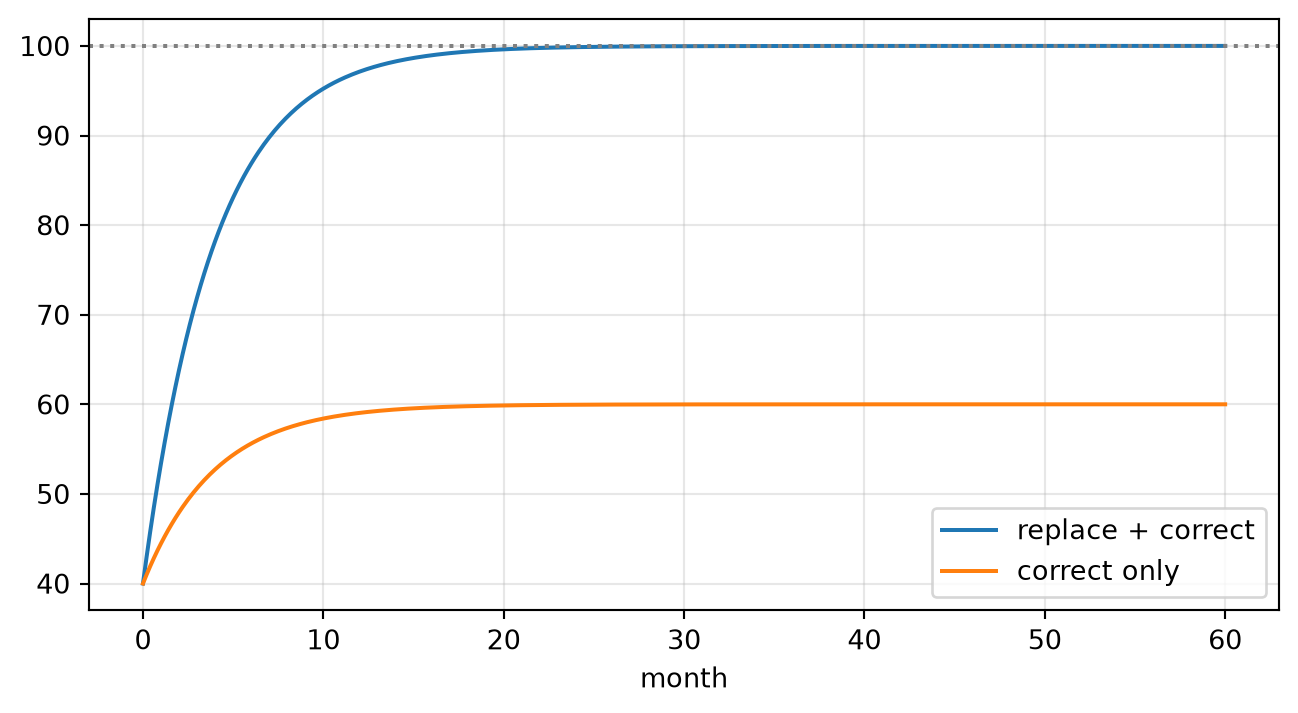

In [4]:
st = lb.molecule("stockAdjust")
fig, ax = plt.subplots(figsize=(8, 4))
for label, kw in [("replace + correct", {}), ("correct only", {"replacement_fraction": 0})]:
    level = st.run(**kw)["Level"]
    level.plot(ax=ax, label=label)
    print(f"{label:<18}: level at month 60 {level.iloc[-1]:5.1f}")
ax.axhline(100, c="grey", ls=":"); ax.set_xlabel("month"); ax.legend(); ax.grid(alpha=0.3)

Without the replacement term, the stock settles at 60, not 100. The reason is arithmetic: the only inflow is `Gap / Adjustment time`, and to match a usage of 10 a month with an adjustment time of 4, the gap has to stay at 40. This **steady-state error** is a sign of a rule that forgot something. Adding the expected usage to the rule removes it.

**Try it.** Without replacement, the gap needed is `usage × adjustment time`. Predict the final level for adjustment times of 2 and 10, then run them. What happens at 10?

<details><summary>Show a worked answer</summary>

At 2 the gap is 10 × 2 = 20, so the level settles at 80, as the run shows. At 10 the formula asks for a gap of 100, which would leave the stock empty. The run ends at about 1: the protected outflow `MIN(10, Level / DT)` cannot take more than is there, so usage itself drops a little below 10 to match the inflow. The rule fails completely, and only the protection from section 1 keeps the numbers meaningful.
</details>

In [5]:
for at in (2, 4, 10):
    d = st.run(replacement_fraction=0, adjustment_time=at)
    print(f"adjustment time {at:>2}: level {d['Level'].iloc[-1]:5.1f}, using up {d['Using up'].iloc[-1]:5.2f}")

adjustment time  2: level  80.0, using up 10.00
adjustment time  4: level  60.0, using up 10.00
adjustment time 10: level   1.0, using up  9.90


## 3. A nonlinear effect with sensible limits

Many relationships are effects: some input, measured relative to a normal value, scales a flow up or down. A good effect function passes through 1 at the normal point, and behaves sensibly at the extremes: no input gives no effect, and a huge input cannot push the flow up without limit. **Effect of a Dimensionless Input** (`effectFunction`) uses `Effect = 2x / (1 + x)`, where `x` is the input relative to its reference.

x = 0.0  : effect 0.000
x = 0.25 : effect 0.400
x = 0.5  : effect 0.667
x = 1.0  : effect 1.000
x = 2.0  : effect 1.333
x = 4.0  : effect 1.600
x = 10.0 : effect 1.818
x = 50.0 : effect 1.961


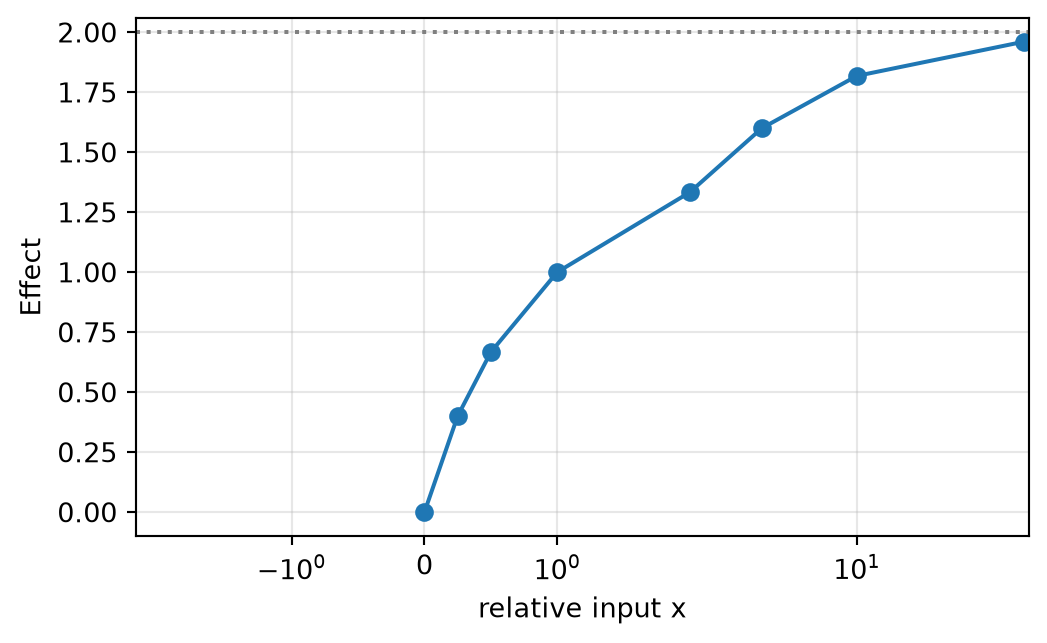

In [6]:
ef = lb.molecule("effectFunction")
inputs = [0, 25, 50, 100, 200, 400, 1000, 5000]
effects = [ef.run(T=0, input=i)["Effect"].iloc[0] for i in inputs]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot([i / 100 for i in inputs], effects, marker="o")
ax.axhline(2, c="grey", ls=":"); ax.set_xscale("symlog"); ax.grid(alpha=0.3)
ax.set_xlabel("relative input x"); ax.set_ylabel("Effect")
for i, e in zip(inputs, effects):
    print(f"x = {i / 100:<5}: effect {e:.3f}")

The curve is 0 at zero input, exactly 1 at the reference, and creeps towards 2 however large the input grows: 50 times the reference only gives 1.96. The `Result` stock settles at `Normal flow × Effect × Drain time = 120 × Effect`, so it can never pass 240. (`T=0` runs a single step, enough to read a variable that does not depend on time.)

**Try it.** A colleague proposes the simpler `Effect = Relative_input`. Copy the model's spec, change that one equation, and compare the two models at 10 times the reference input (`input=1000`).

<details><summary>Show a worked answer</summary>

The linear effect gives 10, and the result heads for 1200; the saturating effect gives 1.818 and a result near 218. Both agree at the reference point, so a test at normal conditions would never tell them apart. Only an extreme-condition test shows that the linear rule lets one input multiply a flow without limit.
</details>

In [7]:
import copy

spec = copy.deepcopy(ef.spec)
for v in spec["model"]["vars"]:
    if v["name"] == "Effect":
        v["eq"] = "Relative_input"
linear = lb.Model.from_spec(spec)

for label, model in [("saturating", ef), ("linear", linear)]:
    d = model.run(input=1000)
    print(f"{label:<10}: effect {d['Effect'].iloc[-1]:6.3f}, result at week 60 {d['Result'].iloc[-1]:7.1f}")

saturating: effect  1.818, result at week 60   218.1
linear    : effect 10.000, result at week 60  1199.4


## 4. Limits inside a feedback loop

**Scheduled Completion & Pressure** (`schedulePressure`) has 400 tasks and a normal pace of 25 a week, so 16 weeks of work. When the deadline is earlier, the team feels `Schedule pressure` (the required pace over the normal pace) and works faster. The effect is clipped: `MAX(0.5, MIN(2, Schedule_pressure))`, so the team can at most double its pace.

In [8]:
sp = lb.molecule("schedulePressure")
print("deadline | 99% done in week | highest pressure | highest effect")
for deadline in (15, 10, 8, 6, 4):
    d = sp.run(scheduled_date=deadline)
    left = d["Work remaining"]
    print(f"{deadline:>8} | {left.index[left <= 4][0]:>16.1f} | {d['Schedule pressure'].max():>16.1f} | {d['Effect of pressure'].max():>14.1f}")

deadline | 99% done in week | highest pressure | highest effect
      15 |             14.9 |              1.1 |            1.1
      10 |             10.0 |              1.6 |            1.6
       8 |              8.0 |              2.0 |            2.0
       6 |              8.0 |             17.6 |            2.0
       4 |              8.0 |             33.6 |            2.0


Down to a deadline of 8 weeks the team meets every deadline by working harder. Below 8, the pressure keeps climbing (it peaks at 17.6 with a 6-week deadline), but the effect is stuck at 2, so the work still takes 8 weeks. The limit in the effect is what makes the model admit that a deadline cannot be met.

**Try it.** Remove the upper limit: change `Effect of pressure` to `MAX(0.5, Schedule_pressure)` in a copy of the spec, and run deadlines of 4 and 1 week. Is the result believable?

<details><summary>Show a worked answer</summary>

Without the limit, a 4-week deadline is met in 4.2 weeks at 100 tasks a week, and a 1-week deadline in 1.4 weeks at a peak of 400 tasks a week, sixteen times the normal pace. No team can do that. The model passes every normal-conditions test and fails the first extreme one, which is why each effect needs explicit limits.
</details>

In [9]:
spec = copy.deepcopy(sp.spec)
for v in spec["model"]["vars"]:
    if v["name"] == "Effect of pressure":
        v["eq"] = "MAX(0.5, Schedule_pressure)"
uncapped = lb.Model.from_spec(spec)

for deadline in (8, 4, 1):
    d = uncapped.run(scheduled_date=deadline)
    left = d["Work remaining"]
    print(f"deadline {deadline}: 99% done in week {left.index[left <= 4][0]:.1f}, peak pace {d['Work rate'].max():.0f} tasks a week")

deadline 8: 99% done in week 8.0, peak pace 50 tasks a week
deadline 4: 99% done in week 4.2, peak pace 100 tasks a week
deadline 1: 99% done in week 1.4, peak pace 400 tasks a week


## Where next

- Back in the app: [Formulating decision rules and nonlinear effects](https://waelrash1.github.io/loopbricks/#/learn/formulation) has the full catalogue of formulations, with diagrams of each molecule.
- The decision rules here assume people use the information they have well. [Bounded rationality and expectations](https://waelrash1.github.io/loopbricks/#/learn/behaviour) looks at how real decision makers anchor, smooth and extrapolate.
- Extreme-condition tests like the ones above are a core part of [Testing and building confidence in models](https://waelrash1.github.io/loopbricks/#/learn/testing). For more on formulation, see Sterman (2000, ch. 13 and 14).